# Notebook Penelitian Tesis — Deteksi Code Smell pada Source Code Python
**Peneliti:** Popo Nugroho  
**NIM:** 14250016  
**Program:** Magister Ilmu Komputer

Notebook ini merupakan artefak replikasi eksperimen untuk penelitian:

> **Analisis Ensemble Learning dan Teknik Penanganan Ketidakseimbangan Kelas untuk Deteksi Code Smell pada Source Code Python**

## Desain eksperimen

- **Dataset:** Large Class (LC) dan Long Method (LM)
- **Eksperimen utama:** 2 dataset × 4 strategi imbalance × 5 model = **40 konfigurasi**
- **Validasi:** Stratified 10-Fold Cross-Validation (`random_state=42`)
- **Preprocessing utama:** Min-Max Scaling → Chi-Square Top-10 → resampling pada training fold
- **Strategi imbalance:** None, SMOTE, ADASYN, Random Over-Sampling (ROS)
- **Model:** Bagging, Gradient Boosting, Max Voting, AdaBoost, XGBoost
- **Metrik primer:** Matthews Correlation Coefficient (MCC)
- **Metrik sekunder:** Macro-F1, Recall kelas positif, AUC-PR
- **Metrik pendukung:** Accuracy, Precision, F1, Cohen's Kappa, AUC-ROC
- **Analisis statistik:** Friedman, Wilcoxon Signed-Rank, koreksi Holm, dan Rank-Biserial Correlation
- **Ablation study:** Baseline, SMOTE only, Chi-Square only, SMOTE + Chi-Square
- **Analisis fitur:** stabilitas Chi-Square, korelasi Pearson, dan Variance Inflation Factor (VIF)

### Prinsip anti-leakage
Seluruh transformasi yang mempelajari parameter dari data—**scaler, feature selector, dan resampling**—dilakukan hanya menggunakan **training fold**. Test fold hanya ditransformasi menggunakan parameter yang diperoleh dari training fold dan **tidak pernah di-resample**.

### Catatan Max Voting
Max Voting direkonstruksi menggunakan Decision Tree, Random Forest, dan Logistic Regression dengan `voting="hard"`. Komposisi ini merupakan **asumsi rekonstruksi eksperimen**, bukan klaim bahwa konfigurasi tersebut identik dengan paper referensi. Karena hard voting tidak menghasilkan probability score, AUC-ROC dan AUC-PR tidak tersedia untuk model ini.


In [ ]:
# Instalasi versi library untuk menjaga reproduktibilitas eksperimen.
# Setelah instalasi pertama di Google Colab, restart runtime jika diminta.
!pip -q install pandas==2.2.3 numpy==2.2.6 scikit-learn==1.8.0 imbalanced-learn==0.14.1 xgboost==3.1.3 scipy==1.17.0 statsmodels==0.14.6


In [ ]:
# ============================================================
# 0. Konfigurasi environment dan library
# ============================================================

import os
import platform
import sys
import time
import warnings
import zipfile

import numpy as np
import pandas as pd

from sklearn.ensemble import (
    AdaBoostClassifier,
    BaggingClassifier,
    GradientBoostingClassifier,
    RandomForestClassifier,
    VotingClassifier,
)
from sklearn.feature_selection import SelectKBest, chi2
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    cohen_kappa_score,
    f1_score,
    matthews_corrcoef,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import MinMaxScaler
from sklearn.tree import DecisionTreeClassifier

from imblearn.over_sampling import ADASYN, SMOTE, RandomOverSampler
from scipy.stats import friedmanchisquare, wilcoxon
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.outliers_influence import variance_inflation_factor
from xgboost import XGBClassifier

import imblearn
import scipy
import sklearn
import statsmodels
import xgboost

warnings.filterwarnings("ignore")

SEED = 42
N_SPLITS = 10
TOP_K = 10
ALPHA = 0.05

np.random.seed(SEED)

print("Environment eksperimen")
print("-" * 50)
print("Python             :", sys.version.split()[0])
print("Platform           :", platform.platform())
print("pandas             :", pd.__version__)
print("NumPy              :", np.__version__)
print("scikit-learn       :", sklearn.__version__)
print("imbalanced-learn   :", imblearn.__version__)
print("XGBoost            :", xgboost.__version__)
print("SciPy              :", scipy.__version__)
print("statsmodels        :", statsmodels.__version__)
print("Random seed        :", SEED)
print("Cross-validation   :", f"Stratified {N_SPLITS}-Fold")
print("Chi-Square Top-K   :", TOP_K)


Environment eksperimen
--------------------------------------------------
Python             : 3.13.18
Platform           : Linux-6.6.159+-x86_64-with-glibc2.39
pandas             : 2.2.3
NumPy              : 2.4.6
scikit-learn       : 1.8.0
imbalanced-learn   : 0.14.1
XGBoost            : 3.1.3
SciPy              : 1.17.0
statsmodels        : 0.14.6
Random seed        : 42
Cross-validation   : Stratified 10-Fold
Chi-Square Top-K   : 10


## 1. Input Dataset

Unggah dua dataset CSV yang digunakan dalam penelitian:

- `Python_LargeClassSmell_Dataset.csv`
- `Python_LongMethodSmell_Dataset.csv`

Notebook mendeteksi dataset berdasarkan nama kolom target, sehingga nama file dapat berbeda selama struktur kolomnya tetap sesuai artefak publik.


In [ ]:
from google.colab import files

uploaded = files.upload()
csv_files = list(uploaded.keys())

print("File CSV yang diterima:", csv_files)


def detect_dataset_file(file_names):
    """Mendeteksi file LC dan LM berdasarkan nama kolom target."""
    lc_file = None
    lm_file = None

    for file_name in file_names:
        preview = pd.read_csv(file_name, nrows=3)
        columns = [column.strip() for column in preview.columns]

        if "LargeClass" in columns:
            lc_file = file_name

        if "Experince Based" in columns or "Experience Based" in columns:
            lm_file = file_name

    return lc_file, lm_file


LC_FILE, LM_FILE = detect_dataset_file(csv_files)

assert LC_FILE is not None, "Dataset Large Class belum terdeteksi."
assert LM_FILE is not None, "Dataset Long Method belum terdeteksi."

print("Large Class :", LC_FILE)
print("Long Method :", LM_FILE)


Saving Python_LargeClassSmell_Dataset.csv to Python_LargeClassSmell_Dataset.csv
Saving Python_LongMethodSmell_Dataset.csv to Python_LongMethodSmell_Dataset.csv
File CSV yang diterima: ['Python_LargeClassSmell_Dataset.csv', 'Python_LongMethodSmell_Dataset.csv']
Large Class : Python_LargeClassSmell_Dataset.csv
Long Method : Python_LongMethodSmell_Dataset.csv


### Alternatif tanpa upload ulang

Jika dataset sudah tersedia di runtime Colab, `LC_FILE` dan `LM_FILE` dapat diarahkan langsung ke lokasi file, misalnya:

```python
LC_FILE = "/content/Python_LargeClassSmell_Dataset.csv"
LM_FILE = "/content/Python_LongMethodSmell_Dataset.csv"
```

Gunakan cara ini hanya jika file yang dimaksud sudah ada di runtime.


## 2. Pembacaan dan Normalisasi Target Dataset

Tahap ini membaca dataset tanpa mengubah nilai prediktor. Nama kolom target Long Method pada artefak publik (`Experince Based` atau `Experience Based`) dinormalisasi menjadi `LongMethod` hanya untuk konsistensi internal notebook.


In [ ]:
def load_datasets(lc_file, lm_file):
    """Membaca dataset LC dan LM serta menormalkan nama kolom target."""
    lc = pd.read_csv(lc_file)
    lm = pd.read_csv(lm_file)

    lc.columns = [column.strip() for column in lc.columns]
    lm.columns = [column.strip() for column in lm.columns]

    if "Experince Based" in lm.columns:
        lm = lm.rename(columns={"Experince Based": "LongMethod"})
    elif "Experience Based" in lm.columns:
        lm = lm.rename(columns={"Experience Based": "LongMethod"})

    assert "LargeClass" in lc.columns, "Kolom target LargeClass tidak ditemukan."
    assert "LongMethod" in lm.columns, "Kolom target LongMethod tidak ditemukan."

    return lc, lm


lc_df, lm_df = load_datasets(LC_FILE, LM_FILE)

datasets = {
    "LC": (lc_df, "LargeClass"),
    "LM": (lm_df, "LongMethod"),
}

print("LC shape:", lc_df.shape)
print("LM shape:", lm_df.shape)

display(lc_df.head())
display(lm_df.head())


LC shape: (1000, 20)
LM shape: (894, 20)


,loc,lloc,scloc,comments,single_comments,multi_comments,blanks,h1,h2,n1,n2,vocabulary,length,calculated_length,volume,difficulty,effort,time,bugs,LargeClass
0,469,247,371,10,17,28,53,11,104,67,109,115,176,734.899478,1204.806249,5.764423,6945.012945,385.834052,0.401602,1
1,141,84,93,1,1,16,31,2,4,3,4,6,7,10.000000,18.094738,1.000000,18.094738,1.005263,0.006032,1
2,473,259,290,51,51,73,59,13,92,56,105,105,161,648.273416,1080.993528,7.418478,8019.326990,445.518166,0.360331,1
3,1267,721,883,78,79,144,161,12,286,175,333,298,508,2376.742752,4175.337608,6.986014,29168.966930,1620.498163,1.391779,1
4,174,114,126,16,18,11,19,8,40,23,45,48,68,236.877124,379.777450,4.500000,1708.998525,94.944363,0.126592,1


,loc,lloc,scloc,comments,single_comments,multi_comments,blanks,h1,h2,n1,n2,vocabulary,length,calculated_length,volume,difficulty,effort,time,bugs,LongMethod
0,235,131,136,9,9,60,30,7,35,21,41,42,62,199.176390,334.323680,4.100000,1370.727089,76.151505,0.111441,1
1,162,64,67,20,20,49,26,9,28,19,38,37,57,163.135263,296.938842,6.107143,1813.447927,100.747107,0.098980,1
2,56,49,47,2,1,0,8,7,27,20,37,34,57,148.033447,289.985382,4.796296,1390.855813,77.269767,0.096662,1
3,49,23,45,3,3,0,1,1,3,2,4,4,6,4.754888,12.000000,0.666667,8.000000,0.444444,0.004000,1
4,166,128,119,23,23,0,24,15,76,58,109,91,167,533.445850,1086.801705,10.756579,11690.268340,649.459352,0.362267,1


## 3. Audit Karakteristik Dataset

Audit dilakukan untuk mendokumentasikan jumlah observasi, prediktor, missing values, duplikasi, dan distribusi kelas sebelum pemodelan.


In [ ]:
def audit_dataset(name, df, target):
    """Meringkas karakteristik dasar dataset tanpa mengubah data."""
    y = df[target]
    X = df.drop(columns=[target])
    class_counts = y.value_counts().to_dict()

    return {
        "Dataset": name,
        "Rows": len(df),
        "Predictors": X.shape[1],
        "Missing_Total": int(df.isna().sum().sum()),
        "Duplicate_Rows": int(df.duplicated().sum()),
        "Class_0": int(class_counts.get(0, 0)),
        "Class_1": int(class_counts.get(1, 0)),
        "Class_1_Percent": float((y == 1).mean() * 100),
    }


audit_df = pd.DataFrame(
    [
        audit_dataset(name, df, target)
        for name, (df, target) in datasets.items()
    ]
)

display(audit_df)
audit_df.to_csv("audit_dataset.csv", index=False)


,Dataset,Rows,Predictors,Missing_Total,Duplicate_Rows,Class_0,Class_1,Class_1_Percent
0,LC,1000,19,0,153,800,200,20.000000
1,LM,894,19,0,78,685,209,23.378076


### Keputusan terhadap duplikasi

Duplikasi **tidak dihapus secara otomatis** pada benchmark utama agar eksperimen tetap menggunakan artefak publik sebagaimana tersedia. Jumlah duplikasi didokumentasikan sebagai ancaman validitas dan dapat dievaluasi melalui sensitivity analysis terpisah.


## 4. Definisi Model dan Strategi Resampling


In [ ]:
MODELS = [
    "Bagging",
    "Gradient Boosting",
    "Max Voting",
    "AdaBoost",
    "XGBoost",
]

IMBALANCE = [
    "None",
    "SMOTE",
    "ADASYN",
    "ROS",
]


def make_model(name):
    """Factory untuk membentuk classifier dengan random seed yang konsisten."""
    if name == "Bagging":
        return BaggingClassifier(random_state=SEED)

    if name == "Gradient Boosting":
        return GradientBoostingClassifier(random_state=SEED)

    if name == "AdaBoost":
        return AdaBoostClassifier(random_state=SEED)

    if name == "XGBoost":
        return XGBClassifier(
            random_state=SEED,
            n_jobs=1,
            eval_metric="logloss",
        )

    if name == "Max Voting":
        # Rekonstruksi eksperimental: komposisi base learner tidak diklaim
        # identik dengan paper referensi.
        estimators = [
            ("dt", DecisionTreeClassifier(random_state=SEED)),
            ("rf", RandomForestClassifier(random_state=SEED)),
            ("lr", LogisticRegression(max_iter=2000, random_state=SEED)),
        ]
        return VotingClassifier(
            estimators=estimators,
            voting="hard",
        )

    raise ValueError(f"Model tidak dikenal: {name}")


def make_resampler(name):
    """Factory untuk strategi penanganan ketidakseimbangan kelas."""
    if name == "None":
        return None
    if name == "SMOTE":
        return SMOTE(random_state=SEED)
    if name == "ADASYN":
        return ADASYN(random_state=SEED)
    if name == "ROS":
        return RandomOverSampler(random_state=SEED)

    raise ValueError(f"Strategi imbalance tidak dikenal: {name}")


## 5. Fungsi Evaluasi

MCC digunakan sebagai **metrik primer**. AUC-ROC dan AUC-PR dihitung hanya ketika classifier menyediakan probability score atau decision score.


In [ ]:
def probability_or_score(model, X):
    """Mengambil skor kelas positif untuk AUC-ROC/AUC-PR jika tersedia."""
    if hasattr(model, "predict_proba"):
        probabilities = model.predict_proba(X)
        if probabilities.ndim == 2 and probabilities.shape[1] >= 2:
            return probabilities[:, 1]

    if hasattr(model, "decision_function"):
        return model.decision_function(X)

    return None


def calculate_metrics(y_true, y_pred, y_score=None):
    """Menghitung seluruh metrik evaluasi pada satu test fold."""
    metrics = {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1": f1_score(y_true, y_pred, zero_division=0),
        "Macro_F1": f1_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0,
        ),
        "Kappa": cohen_kappa_score(y_true, y_pred),
        "MCC": matthews_corrcoef(y_true, y_pred),
    }

    if y_score is not None and len(np.unique(y_true)) == 2:
        metrics["AUC_ROC"] = roc_auc_score(y_true, y_score)
        metrics["AUC_PR"] = average_precision_score(y_true, y_score)
    else:
        metrics["AUC_ROC"] = np.nan
        metrics["AUC_PR"] = np.nan

    return metrics


## 6. Eksperimen Utama — 40 Konfigurasi

Pada setiap fold, pipeline dijalankan dengan urutan:

`training fold → Min-Max Scaling → Chi-Square Top-10 → resampling training → model fitting → evaluasi test fold`

Scaler, feature selector, dan resampler **tidak pernah di-fit menggunakan test fold**.


In [ ]:
def run_main_experiment(datasets):
    """Menjalankan 40 konfigurasi utama dengan Stratified 10-Fold CV."""
    fold_rows = []
    feature_rows = []

    for dataset_name, (df, target) in datasets.items():
        X = df.drop(columns=[target]).copy()
        y = df[target].astype(int).copy()
        feature_names = np.asarray(X.columns)

        cv = StratifiedKFold(
            n_splits=N_SPLITS,
            shuffle=True,
            random_state=SEED,
        )

        for imbalance_name in IMBALANCE:
            for model_name in MODELS:
                print(f"{dataset_name} | {imbalance_name} | {model_name}")

                for fold, (train_idx, test_idx) in enumerate(
                    cv.split(X, y),
                    start=1,
                ):
                    X_train = X.iloc[train_idx].copy()
                    X_test = X.iloc[test_idx].copy()
                    y_train = y.iloc[train_idx].copy()
                    y_test = y.iloc[test_idx].copy()

                    # 1. Scaling: fit hanya pada training fold.
                    scaler = MinMaxScaler()
                    X_train_scaled = scaler.fit_transform(X_train)
                    X_test_scaled = scaler.transform(X_test)

                    # 2. Chi-Square Top-K: fit hanya pada training fold.
                    selector = SelectKBest(
                        score_func=chi2,
                        k=min(TOP_K, X.shape[1]),
                    )
                    X_train_selected = selector.fit_transform(
                        X_train_scaled,
                        y_train,
                    )
                    X_test_selected = selector.transform(X_test_scaled)

                    selected = feature_names[
                        selector.get_support()
                    ].tolist()

                    feature_rows.append(
                        {
                            "Dataset": dataset_name,
                            "Imbalance": imbalance_name,
                            "Model": model_name,
                            "Fold": fold,
                            "Selected_Features": "|".join(selected),
                        }
                    )

                    # 3. Resampling: hanya pada training fold.
                    resampler = make_resampler(imbalance_name)

                    if resampler is not None:
                        X_fit, y_fit = resampler.fit_resample(
                            X_train_selected,
                            y_train,
                        )
                    else:
                        X_fit, y_fit = X_train_selected, y_train

                    # 4. Model fitting.
                    model = make_model(model_name)
                    model.fit(X_fit, y_fit)

                    # 5. Evaluasi pada untouched test fold.
                    y_pred = model.predict(X_test_selected)
                    y_score = probability_or_score(
                        model,
                        X_test_selected,
                    )

                    metrics = calculate_metrics(
                        y_test,
                        y_pred,
                        y_score,
                    )

                    fold_rows.append(
                        {
                            "Dataset": dataset_name,
                            "Imbalance": imbalance_name,
                            "Model": model_name,
                            "Fold": fold,
                            **metrics,
                        }
                    )

    return pd.DataFrame(fold_rows), pd.DataFrame(feature_rows)


start = time.time()

fold_scores, selected_features = run_main_experiment(datasets)

runtime_main = time.time() - start

print(f"Runtime eksperimen utama: {runtime_main:.2f} detik")
print("Jumlah baris fold:", len(fold_scores))

display(fold_scores.head())

fold_scores.to_csv("fold_scores_400_baris.csv", index=False)
selected_features.to_csv("selected_features_per_fold.csv", index=False)


LC | None | Bagging
LC | None | Gradient Boosting
LC | None | Max Voting
LC | None | AdaBoost
LC | None | XGBoost
LC | SMOTE | Bagging
LC | SMOTE | Gradient Boosting
LC | SMOTE | Max Voting
LC | SMOTE | AdaBoost
LC | SMOTE | XGBoost
LC | ADASYN | Bagging
LC | ADASYN | Gradient Boosting
LC | ADASYN | Max Voting
LC | ADASYN | AdaBoost
LC | ADASYN | XGBoost
LC | ROS | Bagging
LC | ROS | Gradient Boosting
LC | ROS | Max Voting
LC | ROS | AdaBoost
LC | ROS | XGBoost
LM | None | Bagging
LM | None | Gradient Boosting
LM | None | Max Voting
LM | None | AdaBoost
LM | None | XGBoost
LM | SMOTE | Bagging
LM | SMOTE | Gradient Boosting
LM | SMOTE | Max Voting
LM | SMOTE | AdaBoost
LM | SMOTE | XGBoost
LM | ADASYN | Bagging
LM | ADASYN | Gradient Boosting
LM | ADASYN | Max Voting
LM | ADASYN | AdaBoost
LM | ADASYN | XGBoost
LM | ROS | Bagging
LM | ROS | Gradient Boosting
LM | ROS | Max Voting
LM | ROS | AdaBoost
LM | ROS | XGBoost
Runtime eksperimen utama: 110.38 detik
Jumlah baris fold: 400


,Dataset,Imbalance,Model,Fold,Accuracy,Precision,Recall,F1,Macro_F1,Kappa,MCC,AUC_ROC,AUC_PR
0,LC,None,Bagging,1,0.91,0.761905,0.80,0.780488,0.861942,0.723926,0.724267,0.945000,0.821553
1,LC,None,Bagging,2,0.93,0.842105,0.80,0.820513,0.888517,0.777070,0.777464,0.983437,0.933991
2,LC,None,Bagging,3,0.91,0.866667,0.65,0.742857,0.844156,0.689655,0.700140,0.946875,0.808904
3,LC,None,Bagging,4,0.87,0.888889,0.40,0.551724,0.737850,0.488189,0.541614,0.852813,0.674016
4,LC,None,Bagging,5,0.91,0.761905,0.80,0.780488,0.861942,0.723926,0.724267,0.966250,0.814304


## 7. Ringkasan Performa Eksperimen Utama

Skor setiap konfigurasi diringkas sebagai mean dan standard deviation dari 10 test fold. Ranking utama ditentukan berdasarkan **Mean MCC**.


In [ ]:
METRIC_COLUMNS = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1",
    "Macro_F1",
    "Kappa",
    "MCC",
    "AUC_ROC",
    "AUC_PR",
]

summary = (
    fold_scores
    .groupby(["Dataset", "Imbalance", "Model"])[METRIC_COLUMNS]
    .agg(["mean", "std"])
)

summary.columns = [
    f"{metric}_{statistic}"
    for metric, statistic in summary.columns
]

summary = summary.reset_index()

display(
    summary.sort_values(
        ["Dataset", "MCC_mean"],
        ascending=[True, False],
    )
)

summary.to_csv("summary_40_konfigurasi.csv", index=False)


# Ringkasan konfigurasi terbaik untuk setiap kriteria.
best_rows = []

for dataset_name in ["LC", "LM"]:
    subset = summary[summary["Dataset"] == dataset_name]

    for metric in [
        "MCC_mean",
        "Accuracy_mean",
        "Recall_mean",
        "Macro_F1_mean",
        "AUC_PR_mean",
    ]:
        valid_subset = subset.dropna(subset=[metric])

        if valid_subset.empty:
            continue

        best = valid_subset.loc[valid_subset[metric].idxmax()]

        best_rows.append(
            {
                "Dataset": dataset_name,
                "Criterion": metric,
                "Imbalance": best["Imbalance"],
                "Model": best["Model"],
                "Value": best[metric],
            }
        )

best_results = pd.DataFrame(best_rows)

display(best_results)
best_results.to_csv("best_results.csv", index=False)


,Dataset,Imbalance,Model,Accuracy_mean,Accuracy_std,Precision_mean,Precision_std,Recall_mean,Recall_std,F1_mean,...,Macro_F1_mean,Macro_F1_std,Kappa_mean,Kappa_std,MCC_mean,MCC_std,AUC_ROC_mean,AUC_ROC_std,AUC_PR_mean,AUC_PR_std
17,LC,SMOTE,Gradient Boosting,0.923000,0.041110,0.786524,0.110924,0.865000,0.127039,0.817559,...,0.884278,0.062957,0.769501,0.124956,0.775534,0.120652,0.961281,0.026190,0.879148,0.071461
9,LC,None,XGBoost,0.928000,0.022010,0.842825,0.072897,0.800000,0.120185,0.813269,...,0.884265,0.039739,0.769231,0.078600,0.774809,0.073132,0.952625,0.034281,0.876293,0.073274
14,LC,ROS,XGBoost,0.926000,0.027162,0.812529,0.078106,0.830000,0.125167,0.814791,...,0.884206,0.047365,0.769006,0.094067,0.773594,0.090819,0.956969,0.033966,0.878303,0.070628
19,LC,SMOTE,XGBoost,0.923000,0.033015,0.790192,0.088040,0.845000,0.121221,0.812419,...,0.881929,0.054862,0.764369,0.109238,0.768159,0.107441,0.956344,0.034295,0.878310,0.072038
8,LC,None,Max Voting,0.929000,0.033483,0.886473,0.085868,0.740000,0.126491,0.802465,...,0.879556,0.062419,0.760191,0.123086,0.767202,0.116808,NaN,NaN,NaN,NaN
13,LC,ROS,Max Voting,0.926000,0.030984,0.831254,0.075386,0.795000,0.136321,0.806389,...,0.880251,0.058077,0.761332,0.114333,0.765564,0.107302,NaN,NaN,NaN,NaN
12,LC,ROS,Gradient Boosting,0.921000,0.038137,0.780494,0.085256,0.845000,0.136321,0.807428,...,0.878794,0.063076,0.758225,0.125279,0.761997,0.122435,0.964687,0.026594,0.892450,0.074349
7,LC,None,Gradient Boosting,0.926000,0.036576,0.851629,0.092299,0.765000,0.147290,0.800106,...,0.877294,0.066588,0.755495,0.131765,0.760869,0.126852,0.964094,0.026034,0.888812,0.071301
11,LC,ROS,Bagging,0.919000,0.018529,0.787845,0.036675,0.820000,0.122927,0.797486,...,0.873352,0.039211,0.747403,0.077039,0.751718,0.070713,0.941500,0.033934,0.845204,0.066218
16,LC,SMOTE,Bagging,0.914000,0.021187,0.776044,0.086800,0.820000,0.094868,0.791561,...,0.868629,0.033947,0.737819,0.067613,0.742550,0.067735,0.948031,0.035479,0.841339,0.070124


,Dataset,Criterion,Imbalance,Model,Value
0,LC,MCC_mean,SMOTE,Gradient Boosting,0.775534
1,LC,Accuracy_mean,None,Max Voting,0.929000
2,LC,Recall_mean,ADASYN,AdaBoost,0.910000
3,LC,Macro_F1_mean,SMOTE,Gradient Boosting,0.884278
4,LC,AUC_PR_mean,ROS,Gradient Boosting,0.892450
5,LM,MCC_mean,SMOTE,AdaBoost,0.667571
6,LM,Accuracy_mean,None,AdaBoost,0.882622
7,LM,Recall_mean,ADASYN,AdaBoost,0.880238
8,LM,Macro_F1_mean,SMOTE,AdaBoost,0.828856
9,LM,AUC_PR_mean,None,Gradient Boosting,0.837646


## 8. Stabilitas Seleksi Fitur Chi-Square

Frekuensi seleksi fitur dihitung pada satu kombinasi referensi (`None + Bagging`) karena pembagian fold dan proses Chi-Square identik untuk kombinasi model/resampling lain pada seed yang sama.


In [ ]:
frequency_rows = []

for dataset_name in ["LC", "LM"]:
    subset = selected_features[
        selected_features["Dataset"] == dataset_name
    ]

    reference = subset[
        (subset["Imbalance"] == "None")
        & (subset["Model"] == "Bagging")
    ]

    selected_feature_names = []

    for feature_string in reference["Selected_Features"]:
        selected_feature_names.extend(feature_string.split("|"))

    counts = pd.Series(selected_feature_names).value_counts()

    for feature, count in counts.items():
        frequency_rows.append(
            {
                "Dataset": dataset_name,
                "Feature": feature,
                "Selected_in_Folds": int(count),
            }
        )

chi2_frequency = pd.DataFrame(frequency_rows)

display(chi2_frequency)
chi2_frequency.to_csv("chi2_frequency.csv", index=False)


,Dataset,Feature,Selected_in_Folds
0,LC,loc,10
1,LC,lloc,10
2,LC,scloc,10
3,LC,comments,10
4,LC,single_comments,10
5,LC,h1,10
6,LC,h2,10
7,LC,vocabulary,10
8,LC,difficulty,10
9,LC,calculated_length,7


## 9. Analisis Korelasi dan Multikolinearitas

- Pasangan fitur dengan `|r| ≥ 0,80` dicatat sebagai korelasi tinggi.
- VIF digunakan sebagai **diagnosis multikolinearitas**, bukan aturan otomatis untuk menghapus fitur.
- Hasil ini dibaca bersama stabilitas Chi-Square dan ablation study.


In [ ]:
correlation_rows = []
vif_rows = []

for dataset_name, (df, target) in datasets.items():
    X = df.drop(columns=[target]).astype(float)

    # --------------------------------------------------------
    # Korelasi Pearson
    # --------------------------------------------------------
    correlation_matrix = X.corr()
    feature_names = list(X.columns)

    for i in range(len(feature_names)):
        for j in range(i + 1, len(feature_names)):
            value = correlation_matrix.iloc[i, j]

            if abs(value) >= 0.80:
                correlation_rows.append(
                    {
                        "Dataset": dataset_name,
                        "Feature_1": feature_names[i],
                        "Feature_2": feature_names[j],
                        "Correlation": value,
                        "Abs_Correlation": abs(value),
                    }
                )

    # --------------------------------------------------------
    # Variance Inflation Factor (VIF)
    # --------------------------------------------------------
    X_vif = (
        X.replace([np.inf, -np.inf], np.nan)
        .dropna()
    )

    for index, feature in enumerate(X_vif.columns):
        try:
            vif_value = variance_inflation_factor(
                X_vif.values,
                index,
            )
        except Exception:
            vif_value = np.inf

        vif_rows.append(
            {
                "Dataset": dataset_name,
                "Feature": feature,
                "VIF": vif_value,
            }
        )


high_correlation = (
    pd.DataFrame(correlation_rows)
    .sort_values(
        ["Dataset", "Abs_Correlation"],
        ascending=[True, False],
    )
)

vif_df = (
    pd.DataFrame(vif_rows)
    .sort_values(
        ["Dataset", "VIF"],
        ascending=[True, False],
    )
)

display(high_correlation.head(30))
display(vif_df.head(30))

high_correlation.to_csv("high_correlation.csv", index=False)
vif_df.to_csv("vif.csv", index=False)


,Dataset,Feature_1,Feature_2,Correlation,Abs_Correlation
83,LC,effort,time,1.000000,1.000000
82,LC,volume,bugs,1.000000,1.000000
59,LC,n2,length,0.999397,0.999397
43,LC,h2,vocabulary,0.999278,0.999278
52,LC,n1,length,0.998005,0.998005
50,LC,n1,n2,0.995213,0.995213
45,LC,h2,calculated_length,0.991626,0.991626
61,LC,n2,volume,0.990671,0.990671
64,LC,n2,bugs,0.990671,0.990671
72,LC,length,volume,0.990027,0.990027


,Dataset,Feature,VIF
17,LC,time,3.002400e+15
16,LC,effort,9.007199e+14
5,LC,multi_comments,6.004800e+13
4,LC,single_comments,4.170000e+13
7,LC,h1,3.784538e+13
10,LC,n2,9.061569e+12
14,LC,volume,4.816684e+12
12,LC,length,2.653078e+12
0,LC,loc,2.511768e+12
8,LC,h2,8.458258e+11


## 10. Friedman Test — Eksperimen Utama

Friedman digunakan sebagai omnibus test pada skor fold yang berpasangan. Untuk metrik yang tidak tersedia pada semua model (terutama AUC-PR pada Max Voting hard-voting), hanya konfigurasi dengan **10 nilai fold valid** yang disertakan.

> Karena training set antar-fold saling overlap, hasil inferensial dibaca secara konservatif dan bersama effect size serta pola performa deskriptif.


In [ ]:
STAT_METRICS = [
    "MCC",
    "Macro_F1",
    "AUC_PR",
    "Accuracy",
]


def valid_fold_values(df, filters, metric):
    """Mengambil skor fold terurut dan mempertahankan hanya array yang finite."""
    subset = df.copy()

    for column, value in filters.items():
        subset = subset[subset[column] == value]

    values = (
        subset
        .sort_values("Fold")[metric]
        .to_numpy(dtype=float)
    )

    if len(values) != N_SPLITS:
        return None

    if not np.isfinite(values).all():
        return None

    return values


friedman_rows = []

for dataset_name in ["LC", "LM"]:
    subset = fold_scores[
        fold_scores["Dataset"] == dataset_name
    ]

    configurations = [
        (imbalance, model)
        for imbalance in IMBALANCE
        for model in MODELS
    ]

    for metric in STAT_METRICS:
        arrays = []

        for imbalance, model in configurations:
            values = valid_fold_values(
                subset,
                {
                    "Imbalance": imbalance,
                    "Model": model,
                },
                metric,
            )

            if values is not None:
                arrays.append(values)

        if len(arrays) >= 3:
            statistic, p_value = friedmanchisquare(*arrays)
        else:
            statistic, p_value = np.nan, np.nan

        friedman_rows.append(
            {
                "Dataset": dataset_name,
                "Metric": metric,
                "N_Configs_Valid": len(arrays),
                "Statistic": statistic,
                "p_value": p_value,
            }
        )

friedman_df = pd.DataFrame(friedman_rows)

display(friedman_df)
friedman_df.to_csv("friedman.csv", index=False)


,Dataset,Metric,N_Configs_Valid,Statistic,p_value
0,LC,MCC,20,52.458775,5.646920e-05
1,LC,Macro_F1,20,50.808730,9.954923e-05
2,LC,AUC_PR,16,52.046625,5.549110e-06
3,LC,Accuracy,20,75.767506,9.861630e-09
4,LM,MCC,20,14.479201,7.550742e-01
5,LM,Macro_F1,20,14.413496,7.590751e-01
6,LM,AUC_PR,16,58.182353,5.164525e-07
7,LM,Accuracy,20,42.809520,1.376310e-03


## 11. Analisis Pairwise — Wilcoxon, Holm, dan Rank-Biserial

Perbandingan dilakukan pada **fold yang sama** untuk model yang sama. Enam pasangan strategi imbalance diuji menggunakan Wilcoxon Signed-Rank. Koreksi Holm diterapkan dalam setiap keluarga `Dataset × Model × Metric`.

Rank-Biserial Correlation digunakan sebagai effect size untuk data berpasangan.


In [ ]:
# ============================================================
# 11. Wilcoxon Signed-Rank + Holm + Rank-Biserial Correlation
# ============================================================

PAIRWISE = [
    ("None", "SMOTE"),
    ("None", "ADASYN"),
    ("None", "ROS"),
    ("SMOTE", "ADASYN"),
    ("SMOTE", "ROS"),
    ("ADASYN", "ROS"),
]

# Metrik yang diuji
STAT_METRICS = ["MCC", "Macro_F1", "AUC_PR", "Accuracy"]


def rank_biserial_from_differences(diff):
    """
    Rank-biserial correlation untuk data berpasangan.

    Interpretasi tanda:
    positif  -> kondisi pertama (a) cenderung lebih tinggi
    negatif  -> kondisi kedua (b) cenderung lebih tinggi

    Nilai absolut:
    < 0.10  : negligible
    < 0.30  : small
    < 0.50  : medium
    >= 0.50 : large
    """

    diff = np.asarray(diff, dtype=float)
    diff = diff[np.isfinite(diff)]

    # Buang selisih nol karena Wilcoxon juga mengabaikan zero differences
    diff = diff[diff != 0]

    if len(diff) == 0:
        return np.nan

    abs_diff = np.abs(diff)

    # Rank manual agar selaras dengan signed-rank
    ranks = pd.Series(abs_diff).rank(method="average").to_numpy()

    W_pos = ranks[diff > 0].sum()
    W_neg = ranks[diff < 0].sum()

    denom = W_pos + W_neg

    if denom == 0:
        return np.nan

    return (W_pos - W_neg) / denom


def interpret_effect_size(r):
    if pd.isna(r):
        return "Not available"

    a = abs(r)

    if a < 0.10:
        return "Negligible"
    elif a < 0.30:
        return "Small"
    elif a < 0.50:
        return "Medium"
    else:
        return "Large"


pair_rows = []

for ds in ["LC", "LM"]:
    for model in MODELS:
        for metric in STAT_METRICS:

            temp_rows = []

            for a, b in PAIRWISE:

                va_df = (
                    fold_scores[
                        (fold_scores["Dataset"] == ds) &
                        (fold_scores["Model"] == model) &
                        (fold_scores["Imbalance"] == a)
                    ][["Fold", metric]]
                    .rename(columns={metric: "A"})
                )

                vb_df = (
                    fold_scores[
                        (fold_scores["Dataset"] == ds) &
                        (fold_scores["Model"] == model) &
                        (fold_scores["Imbalance"] == b)
                    ][["Fold", metric]]
                    .rename(columns={metric: "B"})
                )

                # Pairing berdasarkan fold yang sama
                paired = pd.merge(
                    va_df,
                    vb_df,
                    on="Fold",
                    how="inner"
                )

                # Hanya gunakan pasangan valid
                paired = paired[
                    np.isfinite(paired["A"]) &
                    np.isfinite(paired["B"])
                ].copy()

                va = paired["A"].to_numpy(dtype=float)
                vb = paired["B"].to_numpy(dtype=float)

                n_pairs = len(paired)

                # Default jika tidak dapat diuji
                stat = np.nan
                p_raw = np.nan
                mean_diff = np.nan
                rank_biserial = np.nan
                test_status = "Not tested"

                if n_pairs > 0:

                    diff = va - vb
                    mean_diff = np.mean(diff)

                    # Wilcoxon tidak informatif bila semua selisih = 0
                    if np.allclose(diff, 0):
                        stat = 0.0
                        p_raw = 1.0
                        rank_biserial = 0.0
                        test_status = "All differences zero"

                    else:
                        try:
                            stat, p_raw = wilcoxon(
                                va,
                                vb,
                                zero_method="wilcox",
                                alternative="two-sided",
                                method="auto"
                            )

                            rank_biserial = rank_biserial_from_differences(diff)
                            test_status = "Tested"

                        except Exception as e:
                            test_status = f"Error: {str(e)}"

                temp_rows.append({
                    "Dataset": ds,
                    "Model": model,
                    "Metric": metric,
                    "Comparison": f"{a} vs {b}",
                    "N_Pairs": n_pairs,
                    "Statistic": stat,
                    "p_raw": p_raw,
                    "Mean_Difference": mean_diff,
                    "Rank_Biserial": rank_biserial,
                    "Effect_Size": interpret_effect_size(rank_biserial),
                    "Test_Status": test_status
                })

            # ========================================================
            # Holm hanya untuk p-value VALID
            # ========================================================
            valid_idx = [
                i for i, row in enumerate(temp_rows)
                if np.isfinite(row["p_raw"])
            ]

            if len(valid_idx) > 0:

                valid_p = [temp_rows[i]["p_raw"] for i in valid_idx]

                reject, p_holm, _, _ = multipletests(
                    valid_p,
                    alpha=ALPHA,
                    method="holm"
                )

                for j, idx in enumerate(valid_idx):
                    temp_rows[idx]["p_Holm"] = p_holm[j]
                    temp_rows[idx]["Reject_H0_Holm"] = bool(reject[j])

            # Baris invalid / tidak diuji
            for i, row in enumerate(temp_rows):

                if "p_Holm" not in row:
                    row["p_Holm"] = np.nan
                    row["Reject_H0_Holm"] = False

            pair_rows.extend(temp_rows)


wilcoxon_holm = pd.DataFrame(pair_rows)

# Urutan kolom final
wilcoxon_holm = wilcoxon_holm[
    [
        "Dataset",
        "Model",
        "Metric",
        "Comparison",
        "N_Pairs",
        "Statistic",
        "p_raw",
        "p_Holm",
        "Reject_H0_Holm",
        "Mean_Difference",
        "Rank_Biserial",
        "Effect_Size",
        "Test_Status",
    ]
]

# Simpan semua hasil
wilcoxon_holm.to_csv(
    "wilcoxon_holm_rank_biserial.csv",
    index=False
)

# Tampilkan hanya hasil signifikan
significant_results = wilcoxon_holm[
    wilcoxon_holm["Reject_H0_Holm"] == True
].copy()

print("Jumlah seluruh pairwise test:", len(wilcoxon_holm))
print("Jumlah signifikan setelah Holm:", len(significant_results))

display(significant_results)


Jumlah seluruh pairwise test: 240
Jumlah signifikan setelah Holm: 13


,Dataset,Model,Metric,Comparison,N_Pairs,Statistic,p_raw,p_Holm,Reject_H0_Holm,Mean_Difference,Rank_Biserial,Effect_Size,Test_Status
48,LC,Max Voting,MCC,None vs SMOTE,10,0.0,0.001953,0.011719,True,0.035832,1.000000,Large,Tested
54,LC,Max Voting,Macro_F1,None vs SMOTE,10,1.0,0.003906,0.023438,True,0.016719,0.963636,Large,Tested
66,LC,Max Voting,Accuracy,None vs SMOTE,10,0.0,0.003906,0.023438,True,0.018000,1.000000,Large,Tested
83,LC,AdaBoost,Macro_F1,ADASYN vs ROS,10,1.0,0.003906,0.023438,True,-0.031333,-0.963636,Large,Tested
91,LC,AdaBoost,Accuracy,None vs ADASYN,10,0.0,0.003906,0.023438,True,0.040000,1.000000,Large,Tested
93,LC,AdaBoost,Accuracy,SMOTE vs ADASYN,10,0.0,0.003906,0.023438,True,0.037000,1.000000,Large,Tested
95,LC,AdaBoost,Accuracy,ADASYN vs ROS,10,0.0,0.003906,0.023438,True,-0.029000,-1.000000,Large,Tested
139,LM,Bagging,Accuracy,None vs ADASYN,10,0.0,0.007812,0.046875,True,0.023433,1.000000,Large,Tested
201,LM,AdaBoost,Macro_F1,SMOTE vs ADASYN,10,1.0,0.007812,0.046875,True,0.036405,0.955556,Large,Tested
202,LM,AdaBoost,Macro_F1,SMOTE vs ROS,10,0.0,0.007812,0.046875,True,0.023454,1.000000,Large,Tested


## 12. Ablation Study

Ablation study memisahkan kontribusi SMOTE dan Chi-Square Top-10 melalui empat kondisi:

1. **Baseline** — Min-Max, seluruh 19 prediktor, tanpa SMOTE.
2. **SMOTE only** — Min-Max + SMOTE, tanpa Chi-Square.
3. **Chi-Square only** — Min-Max + Chi-Square Top-10, tanpa SMOTE.
4. **SMOTE + Chi-Square** — Min-Max + Chi-Square Top-10 + SMOTE.

Seluruh fitting dan resampling tetap dilakukan hanya pada training fold.


In [ ]:
ABLATION = {
    "Baseline": {"smote": False, "chi2": False},
    "SMOTE only": {"smote": True, "chi2": False},
    "Chi-Square only": {"smote": False, "chi2": True},
    "SMOTE + Chi-Square": {"smote": True, "chi2": True},
}


def run_ablation(datasets):
    """Menjalankan empat kondisi ablation pada seluruh model dan dataset."""
    rows = []

    for dataset_name, (df, target) in datasets.items():
        X = df.drop(columns=[target]).copy()
        y = df[target].astype(int).copy()

        cv = StratifiedKFold(
            n_splits=N_SPLITS,
            shuffle=True,
            random_state=SEED,
        )

        for condition, config in ABLATION.items():
            for model_name in MODELS:
                print(f"{dataset_name} | {condition} | {model_name}")

                for fold, (train_idx, test_idx) in enumerate(
                    cv.split(X, y),
                    start=1,
                ):
                    X_train = X.iloc[train_idx].copy()
                    X_test = X.iloc[test_idx].copy()
                    y_train = y.iloc[train_idx].copy()
                    y_test = y.iloc[test_idx].copy()

                    # Scaling hanya berdasarkan training fold.
                    scaler = MinMaxScaler()
                    X_train_processed = scaler.fit_transform(X_train)
                    X_test_processed = scaler.transform(X_test)

                    # Optional Chi-Square Top-K.
                    if config["chi2"]:
                        selector = SelectKBest(
                            score_func=chi2,
                            k=min(TOP_K, X.shape[1]),
                        )
                        X_train_processed = selector.fit_transform(
                            X_train_processed,
                            y_train,
                        )
                        X_test_processed = selector.transform(
                            X_test_processed
                        )

                    # Optional SMOTE hanya pada training fold.
                    if config["smote"]:
                        X_train_processed, y_train_fit = SMOTE(
                            random_state=SEED
                        ).fit_resample(
                            X_train_processed,
                            y_train,
                        )
                    else:
                        y_train_fit = y_train

                    model = make_model(model_name)
                    model.fit(X_train_processed, y_train_fit)

                    y_pred = model.predict(X_test_processed)
                    y_score = probability_or_score(
                        model,
                        X_test_processed,
                    )

                    metrics = calculate_metrics(
                        y_test,
                        y_pred,
                        y_score,
                    )

                    rows.append(
                        {
                            "Dataset": dataset_name,
                            "Condition": condition,
                            "Model": model_name,
                            "Fold": fold,
                            **metrics,
                        }
                    )

    return pd.DataFrame(rows)


start = time.time()

ablation_fold = run_ablation(datasets)

runtime_ablation = time.time() - start

print(f"Runtime ablation: {runtime_ablation:.2f} detik")
print("Jumlah baris fold:", len(ablation_fold))

ablation_fold.to_csv(
    "ablation_fold_scores.csv",
    index=False,
)


LC | Baseline | Bagging
LC | Baseline | Gradient Boosting
LC | Baseline | Max Voting
LC | Baseline | AdaBoost
LC | Baseline | XGBoost
LC | SMOTE only | Bagging
LC | SMOTE only | Gradient Boosting
LC | SMOTE only | Max Voting
LC | SMOTE only | AdaBoost
LC | SMOTE only | XGBoost
LC | Chi-Square only | Bagging
LC | Chi-Square only | Gradient Boosting
LC | Chi-Square only | Max Voting
LC | Chi-Square only | AdaBoost
LC | Chi-Square only | XGBoost
LC | SMOTE + Chi-Square | Bagging
LC | SMOTE + Chi-Square | Gradient Boosting
LC | SMOTE + Chi-Square | Max Voting
LC | SMOTE + Chi-Square | AdaBoost
LC | SMOTE + Chi-Square | XGBoost
LM | Baseline | Bagging
LM | Baseline | Gradient Boosting
LM | Baseline | Max Voting
LM | Baseline | AdaBoost
LM | Baseline | XGBoost
LM | SMOTE only | Bagging
LM | SMOTE only | Gradient Boosting
LM | SMOTE only | Max Voting
LM | SMOTE only | AdaBoost
LM | SMOTE only | XGBoost
LM | Chi-Square only | Bagging
LM | Chi-Square only | Gradient Boosting
LM | Chi-Square onl

In [ ]:
ablation_summary = (
    ablation_fold
    .groupby(["Dataset", "Condition", "Model"])[METRIC_COLUMNS]
    .agg(["mean", "std"])
)

ablation_summary.columns = [
    f"{metric}_{statistic}"
    for metric, statistic in ablation_summary.columns
]

ablation_summary = ablation_summary.reset_index()

display(
    ablation_summary.sort_values(
        ["Dataset", "MCC_mean"],
        ascending=[True, False],
    )
)

ablation_summary.to_csv(
    "ablation_summary.csv",
    index=False,
)


# Konfigurasi terbaik untuk setiap kriteria evaluasi.
ablation_best_rows = []

for dataset_name in ["LC", "LM"]:
    subset = ablation_summary[
        ablation_summary["Dataset"] == dataset_name
    ]

    for metric in [
        "MCC_mean",
        "Accuracy_mean",
        "Recall_mean",
        "Macro_F1_mean",
        "AUC_PR_mean",
    ]:
        valid_subset = subset.dropna(subset=[metric])

        if valid_subset.empty:
            continue

        best = valid_subset.loc[valid_subset[metric].idxmax()]

        ablation_best_rows.append(
            {
                "Dataset": dataset_name,
                "Metric": metric.replace("_mean", ""),
                "Condition": best["Condition"],
                "Model": best["Model"],
                "Value": best[metric],
            }
        )

ablation_best_results = pd.DataFrame(ablation_best_rows)

display(ablation_best_results)

ablation_best_results.to_csv(
    "ablation_best_results.csv",
    index=False,
)


,Dataset,Condition,Model,Accuracy_mean,Accuracy_std,Precision_mean,Precision_std,Recall_mean,Recall_std,F1_mean,...,Macro_F1_mean,Macro_F1_std,Kappa_mean,Kappa_std,MCC_mean,MCC_std,AUC_ROC_mean,AUC_ROC_std,AUC_PR_mean,AUC_PR_std
4,LC,Baseline,XGBoost,0.933000,0.030569,0.848737,0.088092,0.815000,0.102875,0.828279,...,0.893299,0.050810,0.786900,0.101260,0.789379,0.099334,0.953438,0.032654,0.878904,0.070419
19,LC,SMOTE only,XGBoost,0.929000,0.022336,0.807470,0.070528,0.855000,0.076194,0.828035,...,0.891626,0.034248,0.783484,0.068465,0.785948,0.068600,0.958750,0.026792,0.881045,0.070947
12,LC,SMOTE + Chi-Square,Gradient Boosting,0.923000,0.041110,0.786524,0.110924,0.865000,0.127039,0.817559,...,0.884278,0.062957,0.769501,0.124956,0.775534,0.120652,0.961281,0.026190,0.879148,0.071461
9,LC,Chi-Square only,XGBoost,0.928000,0.022010,0.842825,0.072897,0.800000,0.120185,0.813269,...,0.884265,0.039739,0.769231,0.078600,0.774809,0.073132,0.952625,0.034281,0.876293,0.073274
16,LC,SMOTE only,Bagging,0.925000,0.029155,0.799419,0.079535,0.845000,0.101242,0.817550,...,0.885120,0.045675,0.770708,0.090867,0.774100,0.088182,0.945656,0.040655,0.839447,0.103629
2,LC,Baseline,Gradient Boosting,0.928000,0.032931,0.852592,0.079347,0.775000,0.123040,0.808537,...,0.882071,0.056503,0.764625,0.112573,0.768240,0.110029,0.961688,0.027593,0.884332,0.075799
14,LC,SMOTE + Chi-Square,XGBoost,0.923000,0.033015,0.790192,0.088040,0.845000,0.121221,0.812419,...,0.881929,0.054862,0.764369,0.109238,0.768159,0.107441,0.956344,0.034295,0.878310,0.072038
8,LC,Chi-Square only,Max Voting,0.929000,0.033483,0.886473,0.085868,0.740000,0.126491,0.802465,...,0.879556,0.062419,0.760191,0.123086,0.767202,0.116808,NaN,NaN,NaN,NaN
17,LC,SMOTE only,Gradient Boosting,0.922000,0.033599,0.780658,0.075052,0.850000,0.113039,0.811766,...,0.881257,0.053041,0.762810,0.105981,0.765516,0.106013,0.962844,0.022682,0.883895,0.074122
7,LC,Chi-Square only,Gradient Boosting,0.926000,0.036576,0.851629,0.092299,0.765000,0.147290,0.800106,...,0.877294,0.066588,0.755495,0.131765,0.760869,0.126852,0.964094,0.026034,0.888812,0.071301


,Dataset,Metric,Condition,Model,Value
0,LC,MCC,Baseline,XGBoost,0.789379
1,LC,Accuracy,Baseline,XGBoost,0.933000
2,LC,Recall,SMOTE + Chi-Square,Gradient Boosting,0.865000
3,LC,Macro_F1,Baseline,XGBoost,0.893299
4,LC,AUC_PR,Chi-Square only,Gradient Boosting,0.888812
5,LM,MCC,SMOTE only,XGBoost,0.894872
6,LM,Accuracy,SMOTE only,XGBoost,0.960811
7,LM,Recall,SMOTE only,AdaBoost,0.971429
8,LM,Macro_F1,SMOTE only,XGBoost,0.946655
9,LM,AUC_PR,Baseline,XGBoost,0.946982


## 13. Analisis Statistik Ablation

### 13.1 Friedman Test
Friedman menguji apakah empat kondisi ablation memiliki perbedaan performa secara keseluruhan untuk setiap `Dataset × Model × Metric`.

### 13.2 Pairwise Wilcoxon + Holm + Rank-Biserial
Jika terdapat perbedaan, analisis pairwise membantu mengidentifikasi kondisi yang berbeda. Semua perbandingan tetap dipasangkan berdasarkan fold yang sama.


In [ ]:
ablation_friedman_rows = []

for dataset_name in ["LC", "LM"]:
    for model_name in MODELS:
        subset = ablation_fold[
            (ablation_fold["Dataset"] == dataset_name)
            & (ablation_fold["Model"] == model_name)
        ]

        for metric in STAT_METRICS:
            arrays = []

            for condition in ABLATION:
                values = valid_fold_values(
                    subset,
                    {"Condition": condition},
                    metric,
                )

                if values is not None:
                    arrays.append(values)

            if len(arrays) >= 3:
                statistic, p_value = friedmanchisquare(*arrays)
            else:
                statistic, p_value = np.nan, np.nan

            ablation_friedman_rows.append(
                {
                    "Dataset": dataset_name,
                    "Model": model_name,
                    "Metric": metric,
                    "N_Conditions_Valid": len(arrays),
                    "Statistic": statistic,
                    "p_value": p_value,
                }
            )

ablation_friedman = pd.DataFrame(ablation_friedman_rows)

display(ablation_friedman)

ablation_friedman.to_csv(
    "ablation_friedman.csv",
    index=False,
)


,Dataset,Model,Metric,N_Conditions_Valid,Statistic,p_value
0,LC,Bagging,MCC,4,5.020408,0.170309
1,LC,Bagging,Macro_F1,4,4.285714,0.232219
2,LC,Bagging,AUC_PR,4,0.360000,0.948376
3,LC,Bagging,Accuracy,4,2.700000,0.440227
4,LC,Gradient Boosting,MCC,4,1.087912,0.779993
5,LC,Gradient Boosting,Macro_F1,4,1.087912,0.779993
6,LC,Gradient Boosting,AUC_PR,4,0.840000,0.839878
7,LC,Gradient Boosting,Accuracy,4,1.256757,0.739426
8,LC,Max Voting,MCC,4,14.257732,0.002575
9,LC,Max Voting,Macro_F1,4,10.484536,0.014866


In [ ]:
ABLATION_COMPARISONS = [
    ("Baseline", "SMOTE only"),
    ("Baseline", "Chi-Square only"),
    ("Baseline", "SMOTE + Chi-Square"),
    ("SMOTE only", "Chi-Square only"),
    ("SMOTE only", "SMOTE + Chi-Square"),
    ("Chi-Square only", "SMOTE + Chi-Square"),
]

STAT_METRICS_ABLATION = [
    "MCC",
    "Macro_F1",
    "AUC_PR",
    "Accuracy",
]

ablation_pair_rows = []

for dataset_name in ["LC", "LM"]:
    for model_name in MODELS:
        for metric in STAT_METRICS_ABLATION:
            family_rows = []

            for condition_a, condition_b in ABLATION_COMPARISONS:
                a = (
                    ablation_fold[
                        (ablation_fold["Dataset"] == dataset_name)
                        & (ablation_fold["Model"] == model_name)
                        & (ablation_fold["Condition"] == condition_a)
                    ][["Fold", metric]]
                    .rename(columns={metric: "A"})
                )

                b = (
                    ablation_fold[
                        (ablation_fold["Dataset"] == dataset_name)
                        & (ablation_fold["Model"] == model_name)
                        & (ablation_fold["Condition"] == condition_b)
                    ][["Fold", metric]]
                    .rename(columns={metric: "B"})
                )

                paired = pd.merge(a, b, on="Fold", how="inner")

                paired = paired[
                    np.isfinite(paired["A"])
                    & np.isfinite(paired["B"])
                ].copy()

                values_a = paired["A"].to_numpy(dtype=float)
                values_b = paired["B"].to_numpy(dtype=float)
                n_pairs = len(paired)

                statistic = np.nan
                p_raw = np.nan
                mean_difference = np.nan
                rank_biserial = np.nan
                test_status = "Not tested"

                if n_pairs > 0:
                    differences = values_a - values_b
                    mean_difference = float(np.mean(differences))

                    if np.allclose(differences, 0):
                        statistic = 0.0
                        p_raw = 1.0
                        rank_biserial = 0.0
                        test_status = "All differences zero"
                    else:
                        try:
                            statistic, p_raw = wilcoxon(
                                values_a,
                                values_b,
                                zero_method="wilcox",
                                alternative="two-sided",
                                method="auto",
                            )
                            rank_biserial = rank_biserial_from_differences(
                                differences
                            )
                            test_status = "Tested"
                        except ValueError:
                            test_status = "Not tested"

                family_rows.append(
                    {
                        "Dataset": dataset_name,
                        "Model": model_name,
                        "Metric": metric,
                        "Comparison": (
                            f"{condition_a} vs {condition_b}"
                        ),
                        "N_Pairs": n_pairs,
                        "Statistic": statistic,
                        "p_raw": p_raw,
                        "Mean_Difference": mean_difference,
                        "Rank_Biserial": rank_biserial,
                        "Effect_Size": interpret_effect_size(
                            rank_biserial
                        ),
                        "Test_Status": test_status,
                    }
                )

            # Holm correction hanya untuk p-value valid dalam keluarga
            # Dataset × Model × Metric.
            valid_indices = [
                index
                for index, row in enumerate(family_rows)
                if np.isfinite(row["p_raw"])
            ]

            if valid_indices:
                valid_p_values = [
                    family_rows[index]["p_raw"]
                    for index in valid_indices
                ]

                reject, p_holm, _, _ = multipletests(
                    valid_p_values,
                    alpha=ALPHA,
                    method="holm",
                )

                for position, index in enumerate(valid_indices):
                    family_rows[index]["p_Holm"] = p_holm[position]
                    family_rows[index]["Reject_H0_Holm"] = bool(
                        reject[position]
                    )

            for row in family_rows:
                if "p_Holm" not in row:
                    row["p_Holm"] = np.nan
                    row["Reject_H0_Holm"] = False

            ablation_pair_rows.extend(family_rows)


ablation_pairwise = pd.DataFrame(ablation_pair_rows)

ablation_pairwise = ablation_pairwise[
    [
        "Dataset",
        "Model",
        "Metric",
        "Comparison",
        "N_Pairs",
        "Statistic",
        "p_raw",
        "p_Holm",
        "Reject_H0_Holm",
        "Mean_Difference",
        "Rank_Biserial",
        "Effect_Size",
        "Test_Status",
    ]
]

ablation_pairwise.to_csv(
    "ablation_pairwise_wilcoxon_holm_rank_biserial.csv",
    index=False,
)

ablation_significant = ablation_pairwise[
    ablation_pairwise["Reject_H0_Holm"]
].copy()

print(
    "Jumlah seluruh pairwise ablation test:",
    len(ablation_pairwise),
)
print(
    "Jumlah signifikan setelah Holm:",
    len(ablation_significant),
)

display(ablation_significant)


Jumlah seluruh pairwise ablation test: 240
Jumlah signifikan setelah Holm: 77


,Dataset,Model,Metric,Comparison,N_Pairs,Statistic,p_raw,p_Holm,Reject_H0_Holm,Mean_Difference,Rank_Biserial,Effect_Size,Test_Status
53,LC,Max Voting,MCC,Chi-Square only vs SMOTE + Chi-Square,10,0.0,0.001953,0.011719,True,0.035832,1.000000,Large,Tested
59,LC,Max Voting,Macro_F1,Chi-Square only vs SMOTE + Chi-Square,10,1.0,0.003906,0.023438,True,0.016719,0.963636,Large,Tested
71,LC,Max Voting,Accuracy,Chi-Square only vs SMOTE + Chi-Square,10,0.0,0.003906,0.023438,True,0.018000,1.000000,Large,Tested
121,LM,Bagging,MCC,Baseline vs Chi-Square only,10,1.0,0.003906,0.019531,True,0.223817,0.963636,Large,Tested
122,LM,Bagging,MCC,Baseline vs SMOTE + Chi-Square,10,0.0,0.003906,0.019531,True,0.233566,1.000000,Large,Tested
...,...,...,...,...,...,...,...,...,...,...,...,...,...
232,LM,XGBoost,AUC_PR,SMOTE only vs SMOTE + Chi-Square,10,1.0,0.003906,0.023438,True,0.119999,0.963636,Large,Tested
235,LM,XGBoost,Accuracy,Baseline vs Chi-Square only,10,1.0,0.003906,0.023438,True,0.081523,0.963636,Large,Tested
236,LM,XGBoost,Accuracy,Baseline vs SMOTE + Chi-Square,10,1.0,0.003906,0.023438,True,0.099451,0.963636,Large,Tested
237,LM,XGBoost,Accuracy,SMOTE only vs Chi-Square only,10,1.0,0.003906,0.023438,True,0.084869,0.963636,Large,Tested


## 14. Visualisasi Hasil Utama

Empat grafik disimpan dalam format PNG 300 DPI:

1. Ranking 20 konfigurasi LC berdasarkan Mean MCC.
2. Ranking 20 konfigurasi LM berdasarkan Mean MCC.
3. Ranking ablation LC berdasarkan Mean MCC.
4. Ranking ablation LM berdasarkan Mean MCC.


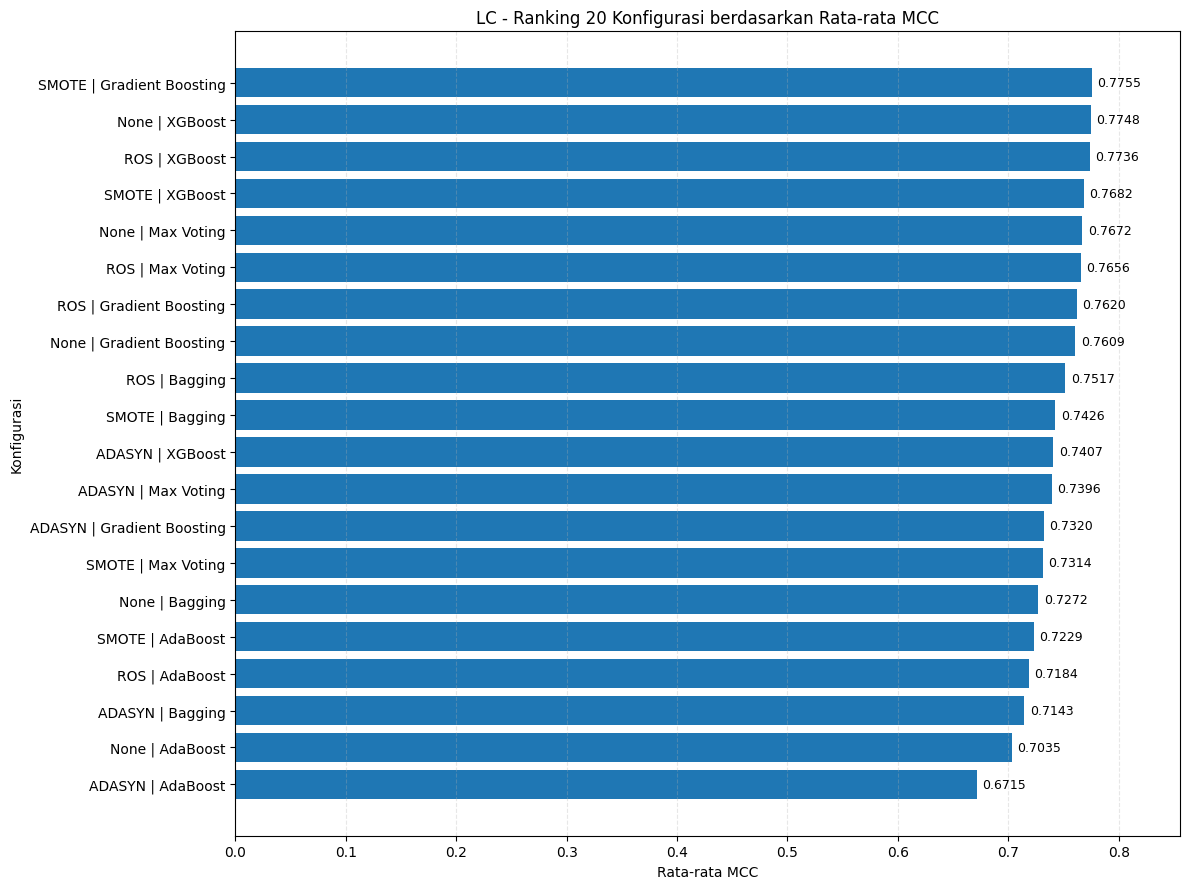

Disimpan: LC_ranking_20_configurations_MCC.png


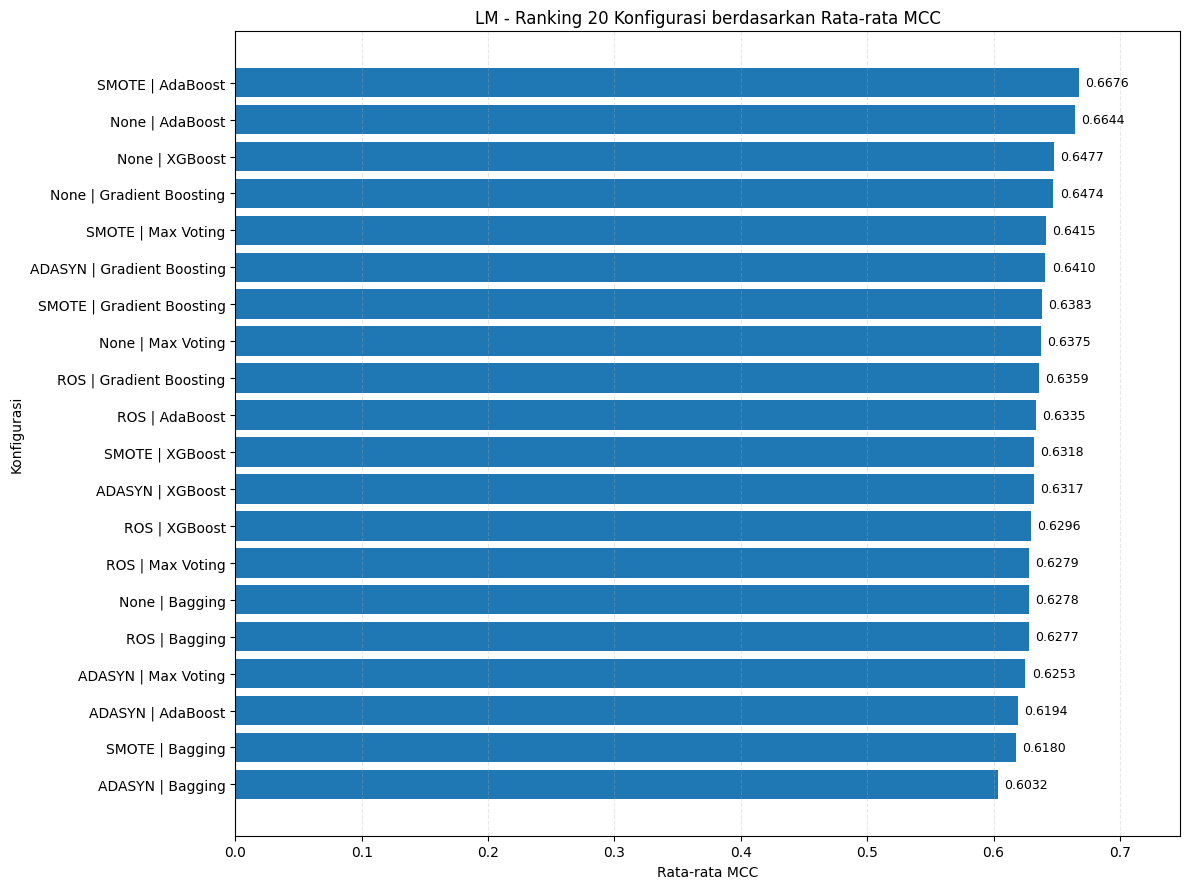

Disimpan: LM_ranking_20_configurations_MCC.png


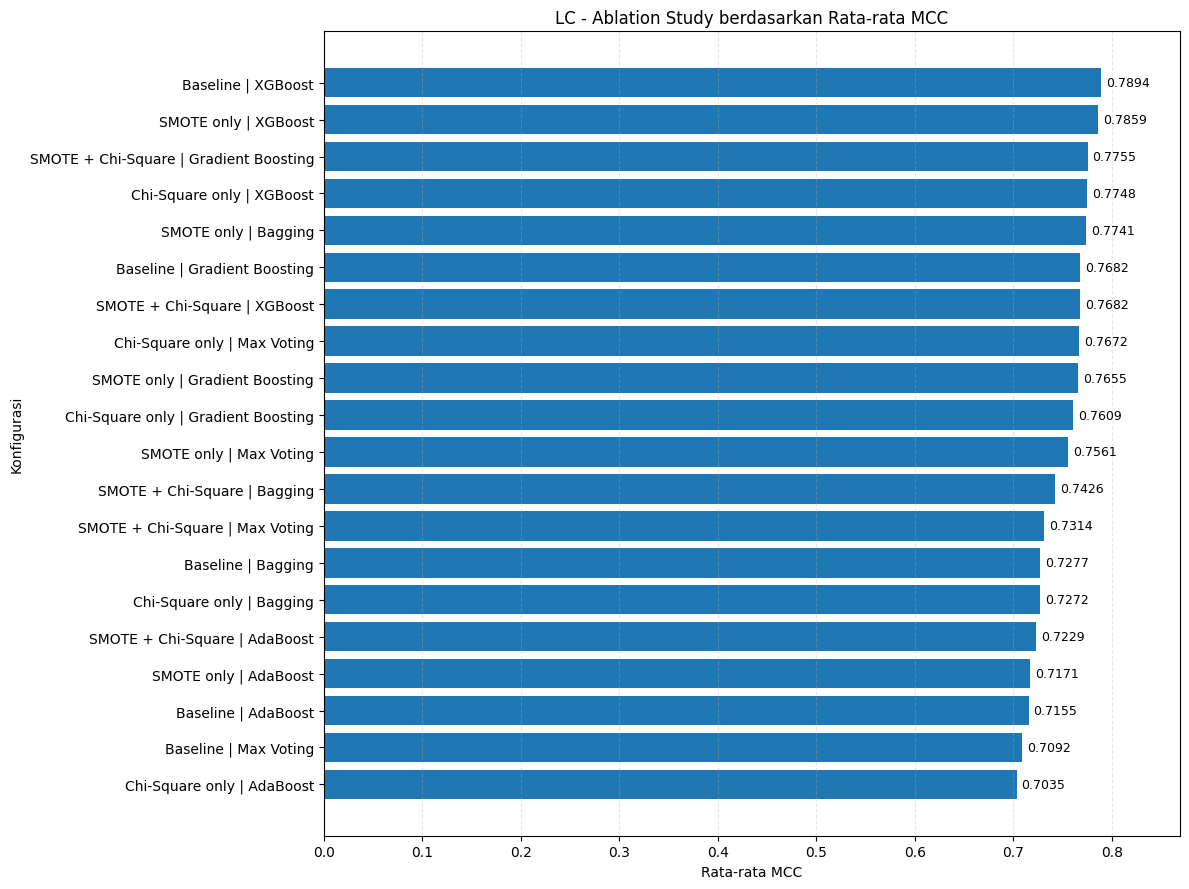

Disimpan: LC_ablation_MCC.png


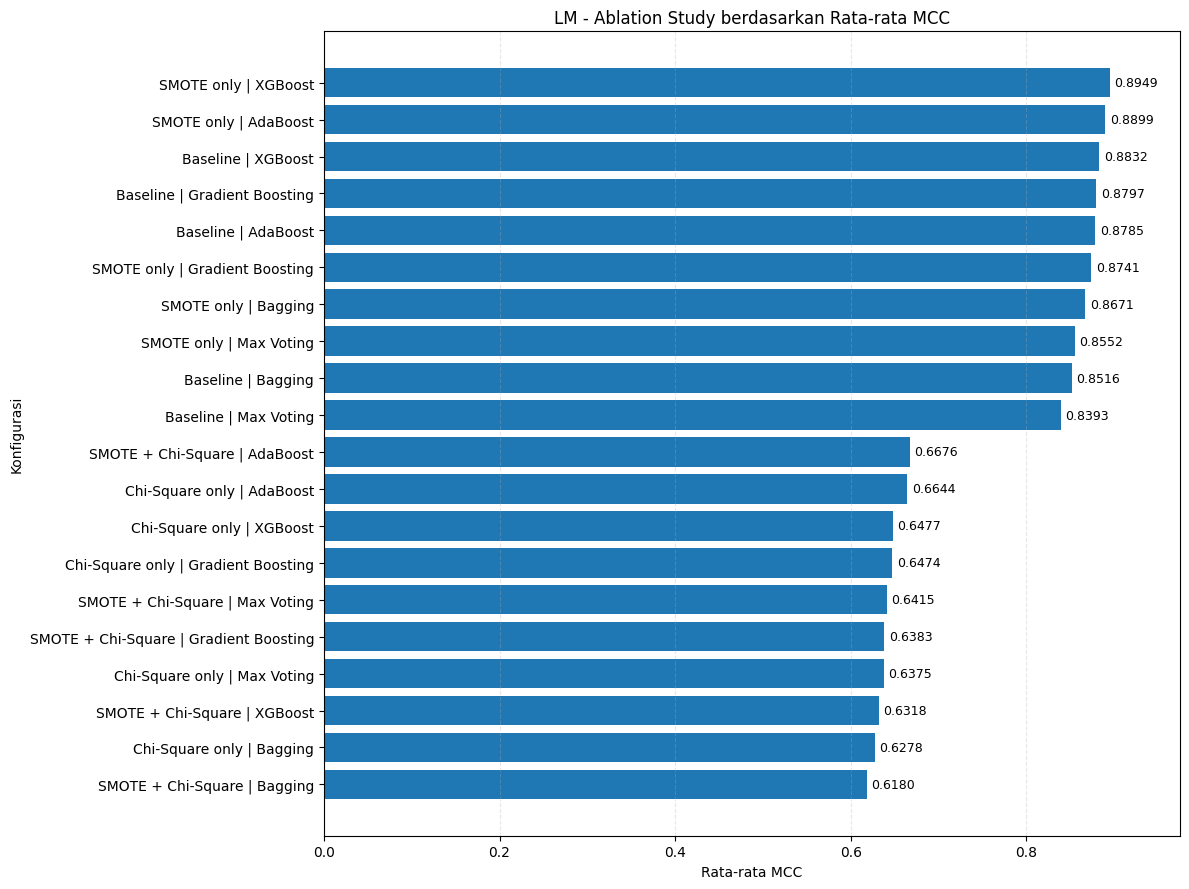

Disimpan: LM_ablation_MCC.png


In [ ]:
import matplotlib.pyplot as plt


def plot_mcc_ranking(
    data,
    dataset_name,
    label_column,
    title,
    filename,
):
    """Membuat horizontal bar chart ranking Mean MCC dan menyimpan 300 DPI."""
    plot_df = (
        data[data["Dataset"] == dataset_name]
        .sort_values("MCC_mean", ascending=False)
        .reset_index(drop=True)
    )

    labels = (
        plot_df[label_column].astype(str)
        + " | "
        + plot_df["Model"].astype(str)
    )

    values = plot_df["MCC_mean"].to_numpy()

    fig, ax = plt.subplots(figsize=(12, 9))
    bars = ax.barh(labels, values)

    ax.set_xlabel("Rata-rata MCC")
    ax.set_ylabel("Konfigurasi")
    ax.set_title(title)
    ax.invert_yaxis()
    ax.grid(axis="x", linestyle="--", alpha=0.3)

    max_value = np.nanmax(values)
    ax.set_xlim(0, min(1.0, max_value + 0.08))

    for bar, value in zip(bars, values):
        if np.isfinite(value):
            ax.text(
                value + 0.005,
                bar.get_y() + bar.get_height() / 2,
                f"{value:.4f}",
                va="center",
                fontsize=9,
            )

    fig.tight_layout()
    fig.savefig(filename, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    print("Disimpan:", filename)


for dataset_name in ["LC", "LM"]:
    plot_mcc_ranking(
        data=summary,
        dataset_name=dataset_name,
        label_column="Imbalance",
        title=(
            f"{dataset_name} - Ranking 20 Konfigurasi "
            "berdasarkan Rata-rata MCC"
        ),
        filename=(
            f"{dataset_name}_ranking_20_configurations_MCC.png"
        ),
    )


for dataset_name in ["LC", "LM"]:
    plot_mcc_ranking(
        data=ablation_summary,
        dataset_name=dataset_name,
        label_column="Condition",
        title=(
            f"{dataset_name} - Ablation Study "
            "berdasarkan Rata-rata MCC"
        ),
        filename=f"{dataset_name}_ablation_MCC.png",
    )


## 15. Validasi dan Sanity Check

Tahap ini memastikan bahwa struktur hasil eksperimen konsisten dengan desain penelitian:

- 400 baris fold pada eksperimen utama.
- 400 baris fold pada ablation study.
- 40 konfigurasi pada masing-masing eksperimen.
- Setiap konfigurasi memiliki tepat 10 fold.
- Semua metrik berada pada rentang matematis yang valid.
- NaN pada AUC-ROC/AUC-PR untuk Max Voting hard-voting diperlakukan sebagai **expected behaviour**, bukan error.

Konfigurasi terbaik dihitung langsung dari output saat notebook dijalankan; tidak bergantung pada angka hard-coded dari eksperimen sebelumnya.


In [ ]:
# ============================================================
# 15. Validasi dan Sanity Check Hasil Eksperimen
# ============================================================

import numpy as np
import pandas as pd

print("=" * 70)
print("VALIDASI HASIL EKSPERIMEN")
print("=" * 70)

# ------------------------------------------------------------
# A. Validasi jumlah data eksperimen
# ------------------------------------------------------------

expected_main_rows = 2 * 4 * 5 * 10
expected_ablation_rows = 2 * 4 * 5 * 10

print("\n[1] JUMLAH BARIS")

print(
    f"Main experiment : {len(fold_scores)} "
    f"(expected {expected_main_rows})"
)

print(
    f"Ablation study  : {len(ablation_fold)} "
    f"(expected {expected_ablation_rows})"
)

assert len(fold_scores) == expected_main_rows, \
    "Jumlah baris main experiment tidak sesuai."

assert len(ablation_fold) == expected_ablation_rows, \
    "Jumlah baris ablation tidak sesuai."

print("✓ Jumlah baris eksperimen sesuai.")


# ------------------------------------------------------------
# B. Validasi jumlah konfigurasi
# ------------------------------------------------------------

main_configs = (
    fold_scores[
        ["Dataset", "Imbalance", "Model"]
    ]
    .drop_duplicates()
)

ablation_configs = (
    ablation_fold[
        ["Dataset", "Condition", "Model"]
    ]
    .drop_duplicates()
)

print("\n[2] JUMLAH KONFIGURASI")

print(
    "Main configurations:",
    len(main_configs),
    "(expected 40)"
)

print(
    "Ablation configurations:",
    len(ablation_configs),
    "(expected 40)"
)

assert len(main_configs) == 40
assert len(ablation_configs) == 40

print("✓ Jumlah konfigurasi sesuai.")


# ------------------------------------------------------------
# C. Cek jumlah fold setiap konfigurasi
# ------------------------------------------------------------

main_fold_check = (
    fold_scores
    .groupby(
        ["Dataset", "Imbalance", "Model"]
    )["Fold"]
    .nunique()
)

ablation_fold_check = (
    ablation_fold
    .groupby(
        ["Dataset", "Condition", "Model"]
    )["Fold"]
    .nunique()
)

assert (main_fold_check == 10).all(), \
    "Ada konfigurasi main yang tidak memiliki 10 fold."

assert (ablation_fold_check == 10).all(), \
    "Ada konfigurasi ablation yang tidak memiliki 10 fold."

print("\n[3] VALIDASI FOLD")
print("✓ Semua konfigurasi memiliki tepat 10 fold.")


# ------------------------------------------------------------
# D. Konfigurasi terbaik MAIN berdasarkan MCC
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("KONFIGURASI TERBAIK MAIN EXPERIMENT BERDASARKAN MCC")
print("=" * 70)

main_best_rows = []

for ds in ["LC", "LM"]:

    best = (
        summary[summary["Dataset"] == ds]
        .sort_values(
            "MCC_mean",
            ascending=False
        )
        .iloc[0]
    )

    main_best_rows.append({
        "Dataset": ds,
        "Imbalance": best["Imbalance"],
        "Model": best["Model"],
        "Accuracy_mean": best["Accuracy_mean"],
        "Recall_mean": best["Recall_mean"],
        "Macro_F1_mean": best["Macro_F1_mean"],
        "MCC_mean": best["MCC_mean"],
        "AUC_PR_mean": best["AUC_PR_mean"]
    })

main_best = pd.DataFrame(main_best_rows)

display(main_best)


# ------------------------------------------------------------
# E. Konfigurasi terbaik ABLATION berdasarkan MCC
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("KONFIGURASI TERBAIK ABLATION BERDASARKAN MCC")
print("=" * 70)

ablation_best_rows = []

for ds in ["LC", "LM"]:

    best = (
        ablation_summary[
            ablation_summary["Dataset"] == ds
        ]
        .sort_values(
            "MCC_mean",
            ascending=False
        )
        .iloc[0]
    )

    ablation_best_rows.append({
        "Dataset": ds,
        "Condition": best["Condition"],
        "Model": best["Model"],
        "Accuracy_mean": best["Accuracy_mean"],
        "Recall_mean": best["Recall_mean"],
        "Macro_F1_mean": best["Macro_F1_mean"],
        "MCC_mean": best["MCC_mean"],
        "AUC_PR_mean": best["AUC_PR_mean"]
    })

ablation_best = pd.DataFrame(
    ablation_best_rows
)

display(ablation_best)


# ------------------------------------------------------------
# F. Validasi nilai metrik
# ------------------------------------------------------------

print("\n[4] RANGE METRIK")

bounded_metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1",
    "Macro_F1",
    "AUC_ROC",
    "AUC_PR"
]

for metric in bounded_metrics:

    valid = fold_scores[metric].dropna()

    if len(valid) > 0:

        assert (
            (valid >= 0) &
            (valid <= 1)
        ).all(), \
        f"{metric} memiliki nilai di luar range 0-1."

print(
    "✓ Accuracy, Precision, Recall, F1, Macro-F1, "
    "AUC-ROC, dan AUC-PR berada pada range yang valid."
)

# MCC dan Kappa boleh berada -1 sampai +1
for metric in ["MCC", "Kappa"]:

    valid = fold_scores[metric].dropna()

    assert (
        (valid >= -1) &
        (valid <= 1)
    ).all(), \
    f"{metric} memiliki nilai di luar range -1 sampai 1."

print("✓ MCC dan Kappa berada pada range yang valid.")


# ------------------------------------------------------------
# G. Cek NaN
# ------------------------------------------------------------

print("\n[5] PEMERIKSAAN NaN")

nan_counts = fold_scores[
    [
        "Accuracy",
        "Precision",
        "Recall",
        "F1",
        "Macro_F1",
        "Kappa",
        "MCC",
        "AUC_ROC",
        "AUC_PR"
    ]
].isna().sum()

display(
    nan_counts.to_frame(
        "Jumlah_NaN"
    )
)

print(
    "\nCatatan: NaN pada AUC_ROC/AUC_PR untuk "
    "Max Voting hard-voting adalah expected behaviour."
)


# ------------------------------------------------------------
# H. Ringkasan sanity check
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("SANITY CHECK SELESAI")
print("=" * 70)

print("✓ 400 main fold rows")
print("✓ 400 ablation fold rows")
print("✓ 40 konfigurasi main")
print("✓ 40 konfigurasi ablation")
print("✓ 10 fold per konfigurasi")
print("✓ Range metrik valid")
print("✓ Konfigurasi terbaik berhasil diidentifikasi")


VALIDASI HASIL EKSPERIMEN

[1] JUMLAH BARIS
Main experiment : 400 (expected 400)
Ablation study  : 400 (expected 400)
✓ Jumlah baris eksperimen sesuai.

[2] JUMLAH KONFIGURASI
Main configurations: 40 (expected 40)
Ablation configurations: 40 (expected 40)
✓ Jumlah konfigurasi sesuai.

[3] VALIDASI FOLD
✓ Semua konfigurasi memiliki tepat 10 fold.

KONFIGURASI TERBAIK MAIN EXPERIMENT BERDASARKAN MCC


,Dataset,Imbalance,Model,Accuracy_mean,Recall_mean,Macro_F1_mean,MCC_mean,AUC_PR_mean
0,LC,SMOTE,Gradient Boosting,0.923000,0.865000,0.884278,0.775534,0.879148
1,LM,SMOTE,AdaBoost,0.868127,0.823095,0.828856,0.667571,0.828257



KONFIGURASI TERBAIK ABLATION BERDASARKAN MCC


,Dataset,Condition,Model,Accuracy_mean,Recall_mean,Macro_F1_mean,MCC_mean,AUC_PR_mean
0,LC,Baseline,XGBoost,0.933000,0.815000,0.893299,0.789379,0.878904
1,LM,SMOTE only,XGBoost,0.960811,0.952381,0.946655,0.894872,0.946358



[4] RANGE METRIK
✓ Accuracy, Precision, Recall, F1, Macro-F1, AUC-ROC, dan AUC-PR berada pada range yang valid.
✓ MCC dan Kappa berada pada range yang valid.

[5] PEMERIKSAAN NaN


,Jumlah_NaN
Accuracy,0
Precision,0
Recall,0
F1,0
Macro_F1,0
Kappa,0
MCC,0
AUC_ROC,80
AUC_PR,80



Catatan: NaN pada AUC_ROC/AUC_PR untuk Max Voting hard-voting adalah expected behaviour.

SANITY CHECK SELESAI
✓ 400 main fold rows
✓ 400 ablation fold rows
✓ 40 konfigurasi main
✓ 40 konfigurasi ablation
✓ 10 fold per konfigurasi
✓ Range metrik valid
✓ Konfigurasi terbaik berhasil diidentifikasi


## 16. Ekspor Artefak Penelitian

Seluruh tabel hasil, statistik, konfigurasi eksperimen, dan grafik dikemas menjadi satu ZIP agar mudah diarsipkan dan digunakan dalam penulisan Bab IV.


In [ ]:
# ============================================================
# 16. Simpan Seluruh Hasil Penelitian sebagai ZIP
# ============================================================

import os
import zipfile
import pandas as pd

# ------------------------------------------------------------
# A. Simpan konfigurasi eksperimen
# ------------------------------------------------------------

config = pd.DataFrame([
    ["Random seed", SEED],
    ["Cross-validation", f"Stratified {N_SPLITS}-Fold, shuffle=True"],
    ["Feature selection utama", f"Chi-Square Top-{TOP_K}"],
    ["Main imbalance", "None, SMOTE, ADASYN, ROS"],
    ["Models", ", ".join(MODELS)],
    ["Primary metric", "MCC"],
    ["Secondary metrics", "Macro-F1, Recall, AUC-PR"],
    ["Supporting metrics", "Accuracy, Precision, F1, Kappa, AUC-ROC"],
    ["Runtime main experiment (seconds)", runtime_main],
    ["Runtime ablation study (seconds)", runtime_ablation],
])

config.columns = ["Item", "Value"]

config.to_csv(
    "configuration_colab.csv",
    index=False
)


# ------------------------------------------------------------
# B. Simpan tabel hasil terbaik final
# ------------------------------------------------------------

main_best.to_csv(
    "main_best_results_final.csv",
    index=False
)

ablation_best.to_csv(
    "ablation_best_results_final.csv",
    index=False
)


# ------------------------------------------------------------
# C. Daftar seluruh artefak penelitian
# ------------------------------------------------------------

output_files = [

    # Dataset audit
    "audit_dataset.csv",

    # Main experiment
    "fold_scores_400_baris.csv",
    "selected_features_per_fold.csv",
    "summary_40_konfigurasi.csv",
    "main_best_results_final.csv",

    # Feature analysis
    "chi2_frequency.csv",
    "high_correlation.csv",
    "vif.csv",

    # Main statistical analysis
    "friedman.csv",
    "wilcoxon_holm_rank_biserial.csv",

    # Ablation study
    "ablation_fold_scores.csv",
    "ablation_summary.csv",
    "ablation_best_results_final.csv",
    "ablation_friedman.csv",
    "ablation_pairwise_wilcoxon_holm_rank_biserial.csv",

    # Experimental configuration
    "configuration_colab.csv",

    # Grafik final 300 DPI
    "LC_ranking_20_configurations_MCC.png",
    "LM_ranking_20_configurations_MCC.png",
    "LC_ablation_MCC.png",
    "LM_ablation_MCC.png",
]


# ------------------------------------------------------------
# D. Cek keberadaan seluruh file
# ------------------------------------------------------------

existing_files = []
missing_files = []

for f in output_files:
    if os.path.exists(f):
        existing_files.append(f)
    else:
        missing_files.append(f)

print("=" * 70)
print("PEMERIKSAAN ARTEFAK PENELITIAN")
print("=" * 70)

print(f"\nFile ditemukan : {len(existing_files)}")
print(f"File tidak ditemukan : {len(missing_files)}")

if missing_files:
    print("\nFile yang tidak ditemukan:")
    for f in missing_files:
        print(" -", f)

print("\nFile yang akan dimasukkan ke ZIP:")
for f in existing_files:
    print(" ✓", f)


# ------------------------------------------------------------
# E. Buat README ringkas
# ------------------------------------------------------------

readme_text = """
HASIL PENELITIAN CODE SMELL PYTHON
==================================

Judul:
Analisis Ensemble Learning dan Teknik Penanganan Ketidakseimbangan
Kelas untuk Deteksi Code Smell pada Source Code Python

Dataset:
1. Large Class (LC)
2. Long Method (LM)

Eksperimen Utama:
2 dataset × 4 imbalance strategies × 5 models × 10 folds
= 400 fold evaluation rows

Strategi Imbalance:
- None
- SMOTE
- ADASYN
- Random Over Sampling (ROS)

Model:
- Bagging
- Gradient Boosting
- Max Voting
- AdaBoost
- XGBoost

Primary Metric:
- Matthews Correlation Coefficient (MCC)

Secondary Metrics:
- Macro-F1
- Recall
- AUC-PR

Ablation Study:
- Baseline
- SMOTE only
- Chi-Square only
- SMOTE + Chi-Square

Statistical Analysis:
- Friedman Test
- Wilcoxon Signed-Rank Test
- Holm Correction
- Rank-Biserial Correlation

Catatan:
AUC-ROC dan AUC-PR tidak tersedia untuk Max Voting hard-voting
karena model tersebut tidak menghasilkan probabilistic score.

Seluruh preprocessing yang dapat menyebabkan data leakage
dilakukan hanya menggunakan training fold.
"""

with open(
    "README_HASIL_PENELITIAN.txt",
    "w",
    encoding="utf-8"
) as f:
    f.write(readme_text)

existing_files.append(
    "README_HASIL_PENELITIAN.txt"
)


# ------------------------------------------------------------
# F. Buat ZIP
# ------------------------------------------------------------

zip_name = "HASIL_PENELITIAN_CODE_SMELL_POPO_NUGROHO_FINAL.zip"

with zipfile.ZipFile(
    zip_name,
    "w",
    zipfile.ZIP_DEFLATED
) as z:

    for f in existing_files:
        z.write(
            f,
            arcname=os.path.basename(f)
        )


# ------------------------------------------------------------
# G. Validasi ZIP
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("ZIP BERHASIL DIBUAT")
print("=" * 70)

print("Nama ZIP :", zip_name)
print("Jumlah file di ZIP :", len(existing_files))

with zipfile.ZipFile(zip_name, "r") as z:
    print("\nIsi ZIP:")
    for name in z.namelist():
        print(" ✓", name)


# ------------------------------------------------------------
# H. Download otomatis di Google Colab
# ------------------------------------------------------------

from google.colab import files

files.download(zip_name)


PEMERIKSAAN ARTEFAK PENELITIAN

File ditemukan : 20
File tidak ditemukan : 0

File yang akan dimasukkan ke ZIP:
 ✓ audit_dataset.csv
 ✓ fold_scores_400_baris.csv
 ✓ selected_features_per_fold.csv
 ✓ summary_40_konfigurasi.csv
 ✓ main_best_results_final.csv
 ✓ chi2_frequency.csv
 ✓ high_correlation.csv
 ✓ vif.csv
 ✓ friedman.csv
 ✓ wilcoxon_holm_rank_biserial.csv
 ✓ ablation_fold_scores.csv
 ✓ ablation_summary.csv
 ✓ ablation_best_results_final.csv
 ✓ ablation_friedman.csv
 ✓ ablation_pairwise_wilcoxon_holm_rank_biserial.csv
 ✓ configuration_colab.csv
 ✓ LC_ranking_20_configurations_MCC.png
 ✓ LM_ranking_20_configurations_MCC.png
 ✓ LC_ablation_MCC.png
 ✓ LM_ablation_MCC.png

ZIP BERHASIL DIBUAT
Nama ZIP : HASIL_PENELITIAN_CODE_SMELL_POPO_NUGROHO_FINAL.zip
Jumlah file di ZIP : 21

Isi ZIP:
 ✓ audit_dataset.csv
 ✓ fold_scores_400_baris.csv
 ✓ selected_features_per_fold.csv
 ✓ summary_40_konfigurasi.csv
 ✓ main_best_results_final.csv
 ✓ chi2_frequency.csv
 ✓ high_correlation.csv
 ✓ vif.cs

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 17. Panduan Interpretasi Hasil

Prioritas interpretasi:

1. **MCC** — metrik primer untuk membandingkan performa pada data imbalance.
2. **Macro-F1** — keseimbangan performa lintas kelas.
3. **Recall kelas smelly** — kemampuan mendeteksi kelas positif.
4. **AUC-PR** — kualitas pemisahan kelas positif pada kondisi imbalance; tidak tersedia untuk Max Voting hard-voting.
5. **Accuracy** — metrik pendukung dan tidak digunakan sebagai satu-satunya dasar kesimpulan.

### Pertanyaan analitis utama

- Apakah SMOTE meningkatkan MCC dibanding `None` secara konsisten?
- Apakah ADASYN atau ROS memberikan keuntungan yang stabil?
- Apakah efek strategi imbalance berubah menurut classifier dan dataset?
- Fitur apa yang stabil dipilih oleh Chi-Square?
- Seberapa kuat multikolinearitas antar software metrics?
- Apakah Chi-Square Top-10 membantu atau menurunkan performa?
- Apakah perbedaan performa didukung oleh Friedman dan pairwise Wilcoxon-Holm?
- Apakah effect size Rank-Biserial menunjukkan perbedaan yang bermakna secara praktis?

> Hasil uji statistik pada 10-fold CV harus diinterpretasikan secara konservatif karena training set antar-fold saling overlap.
